## Test training


In [1]:
%load_ext autoreload
%autoreload 1

%aimport quantdata
%aimport quantdata.dysanos
%aimport quantdata.utils.backbone
%aimport quantdata.torch
%aimport quantdata.torch.bbtorch
%aimport quantdata.torch.ffw
%aimport quantdata.dysanos.simple
%aimport quantdata.dysanos.simple.sampler
%aimport quantdata.dysanos.simple.model
%aimport quantdata.dysanos.simple.trainer
%aimport quantdata.dysanos.simple.aec

from quantdata.dysanos.simple.aec import load_data
sampler = load_data(["SPX"])
print("/done")

00: Importing torch...done; this took 0.00262ms.
00: Generating samples for 1 tickers SPX with from 2015-01-01 to 2025-07-01... done; this took 0.25s.
00: Found the following number of samples per ticker: SPX: 2617.
00: Found date range 2015-01-02 to 2025-07-01 with 2617 total dates. First validation date for 25 steps per sample is 2023-05-01.
00: Using up to 1000 options per date.
01:   Ticker SPX: using 411 training samples (accross 2079 training dates), and 103 validation samples (accross 538 validation dates).
00: Created 411 training samples and 103 validation samples based on the date split at 2023-05-01. That implies 20% of all samples are validation samples.
00: Total time taken: 0.28s.
/done


## AEC

Cleaning up memory... done.
Model AEC train_vol_vol_simple 1.2 [9cdf2f11|fa6007dd3ce42e6d] created.
00: Trainer for 'AEC train_vol_vol_simple 1.2 [9cdf2f11|fa6007dd3ce42e6d]'
00: ======================================================================
01:   Model is ready. Current epoch to train is 0.
01:   Experiment path is /media/storage/quantdata/experiments/dysanos/simple/fa6007dd3ce42e6d/v1/train_vol_vol_simple 01994b44/.
00: Launching 'AEC train_vol_vol_simple 1.2 [9cdf2f11|fa6007dd3ce42e6d]' training for 1000 epochs over 411 training and 103 validation samples, using a mini bastch size of 128 for 100 batches per epoch, and a batch size of 512 for valuation.
01:   This model has 30785 parameters.
01:   Starting afresh.
00: Training 'train_vol_vol_simple' epoch 1/1000 error avg trn 552.6; val 50.77/66.83 [13s 0.43s 0.43s]. LR: 1.00e-03, GN 13.32, excess_weighted: 0.003715/0.003239, excess_weighted_avg: 0.004212/0.003387, excess_spread: 54.99/67.15, excess_spread_avg: 51/67.15, exce

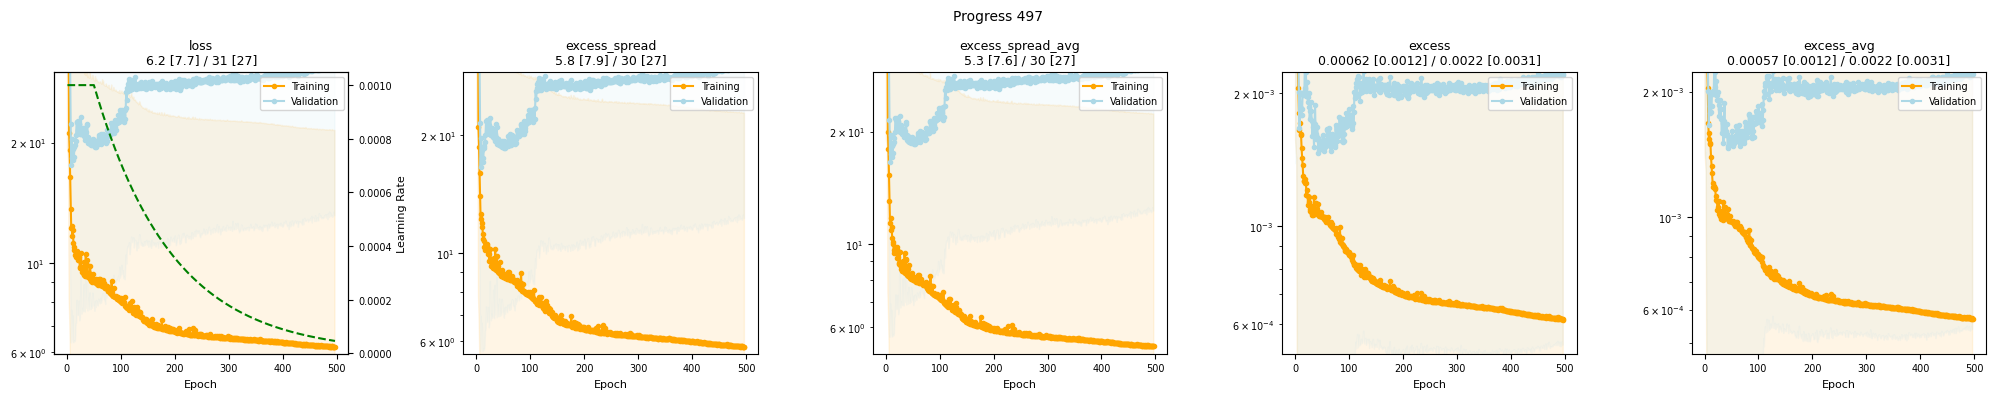

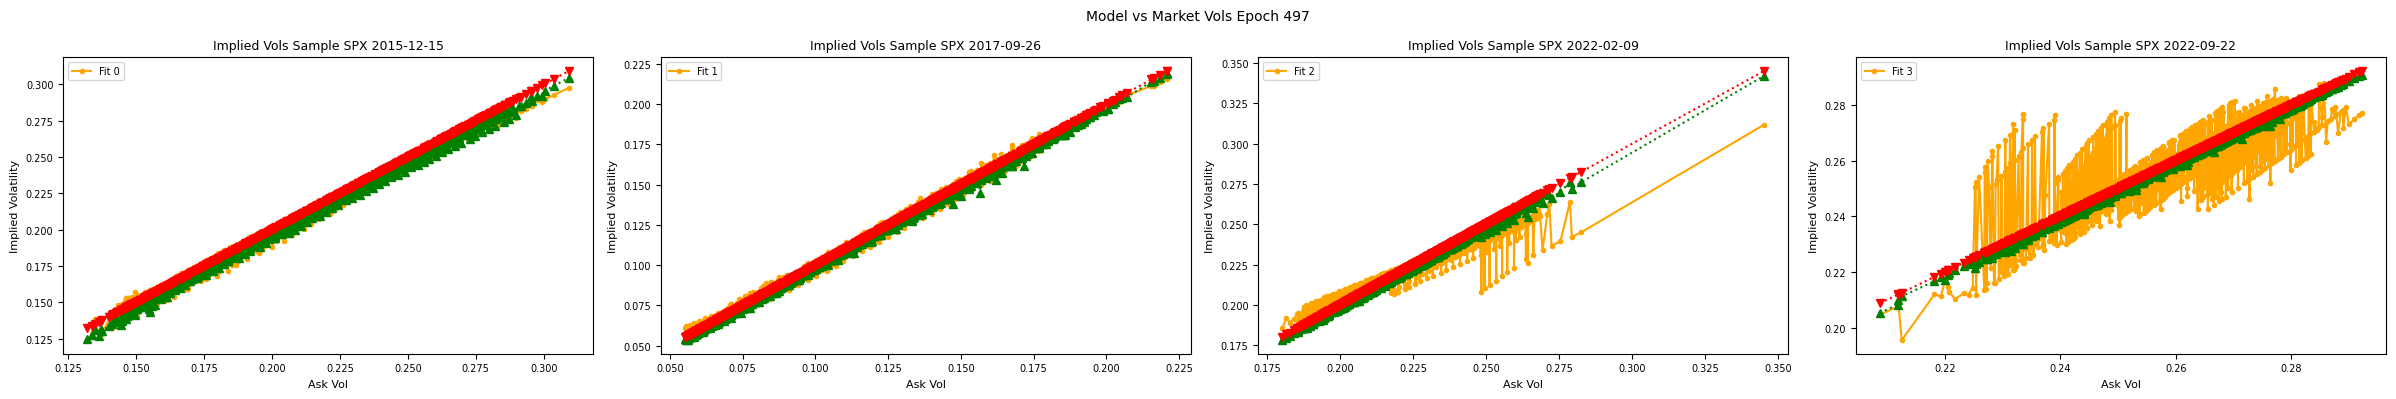

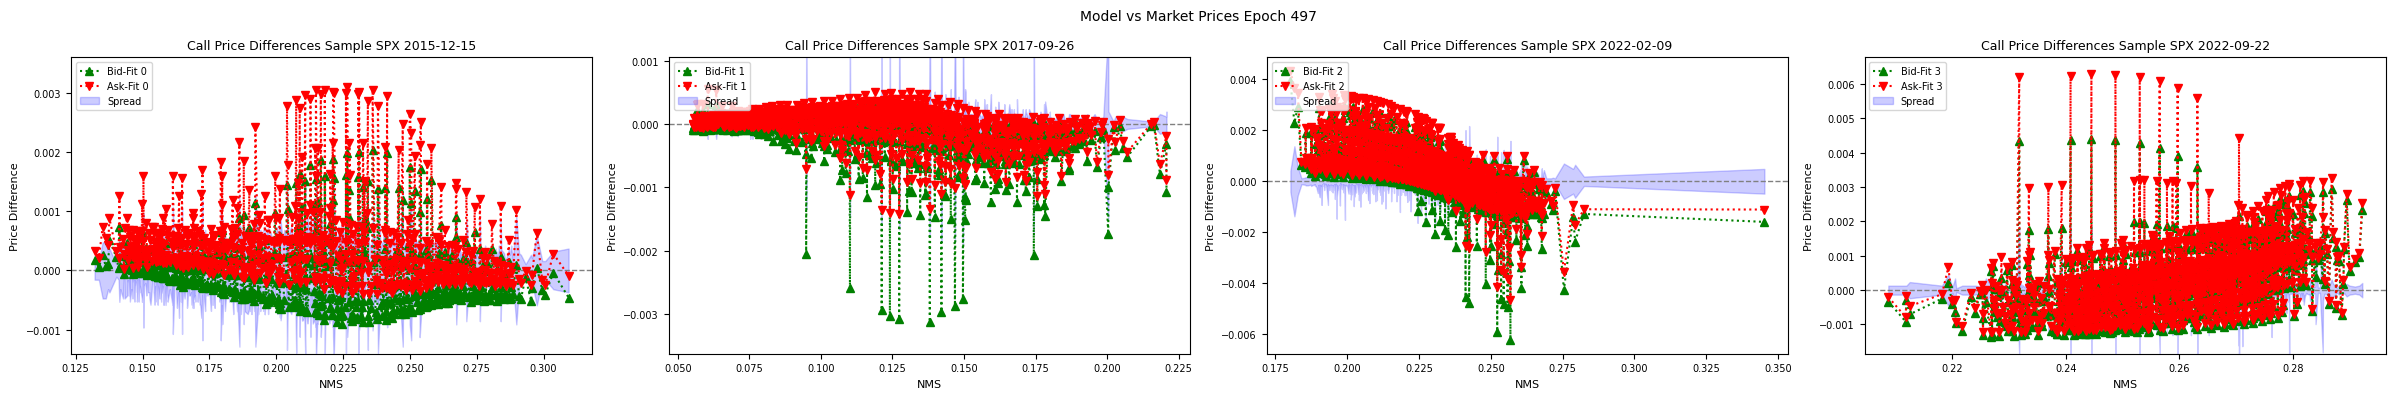

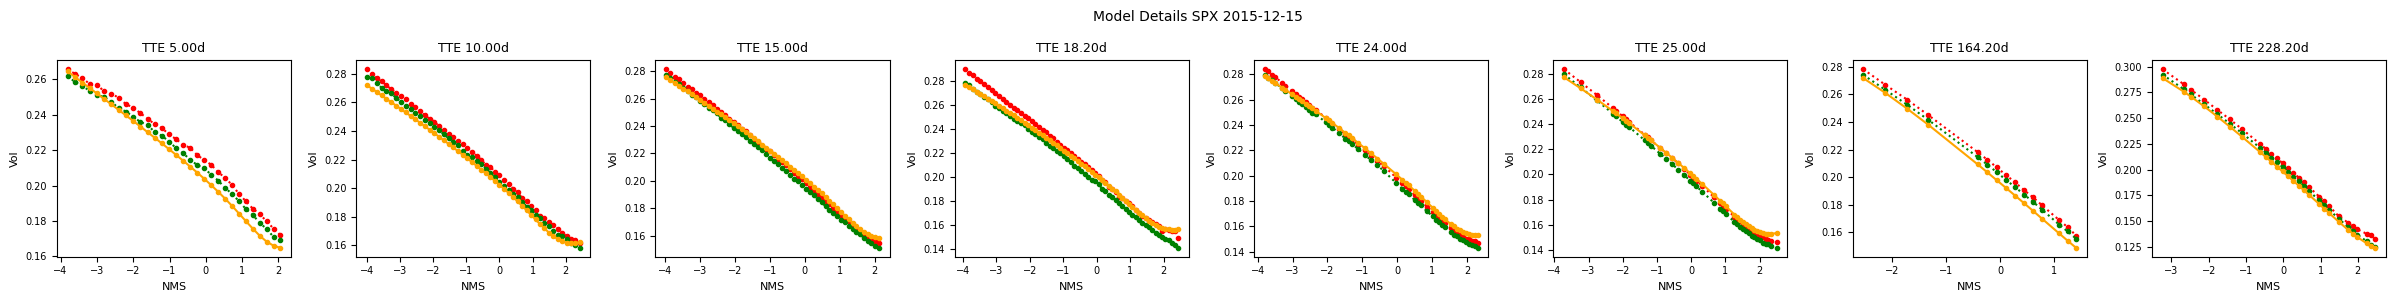

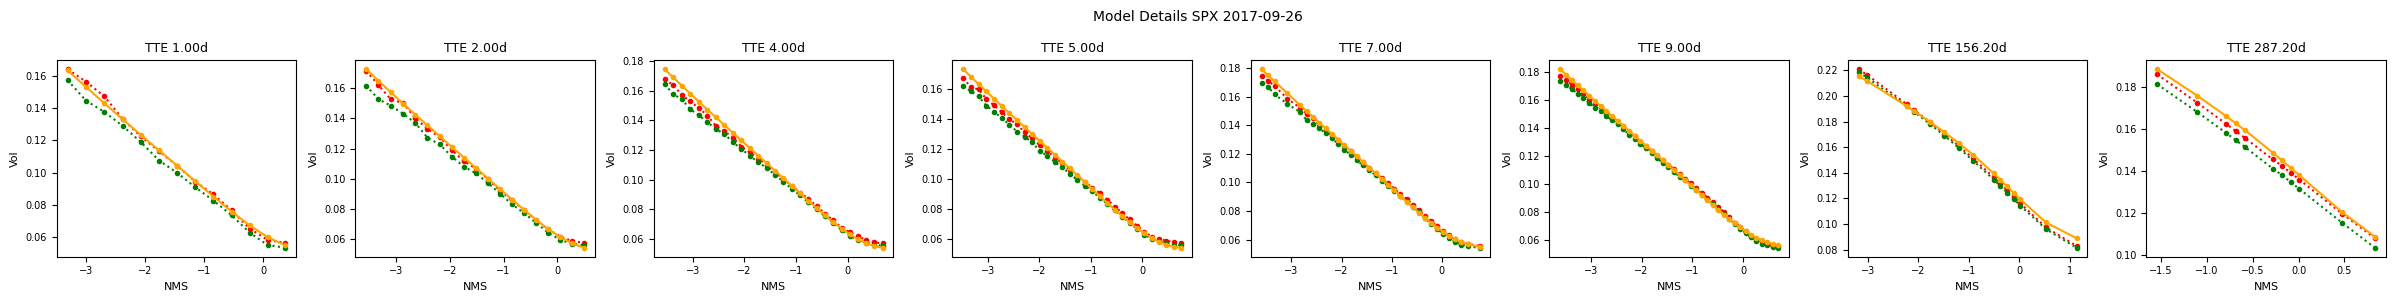

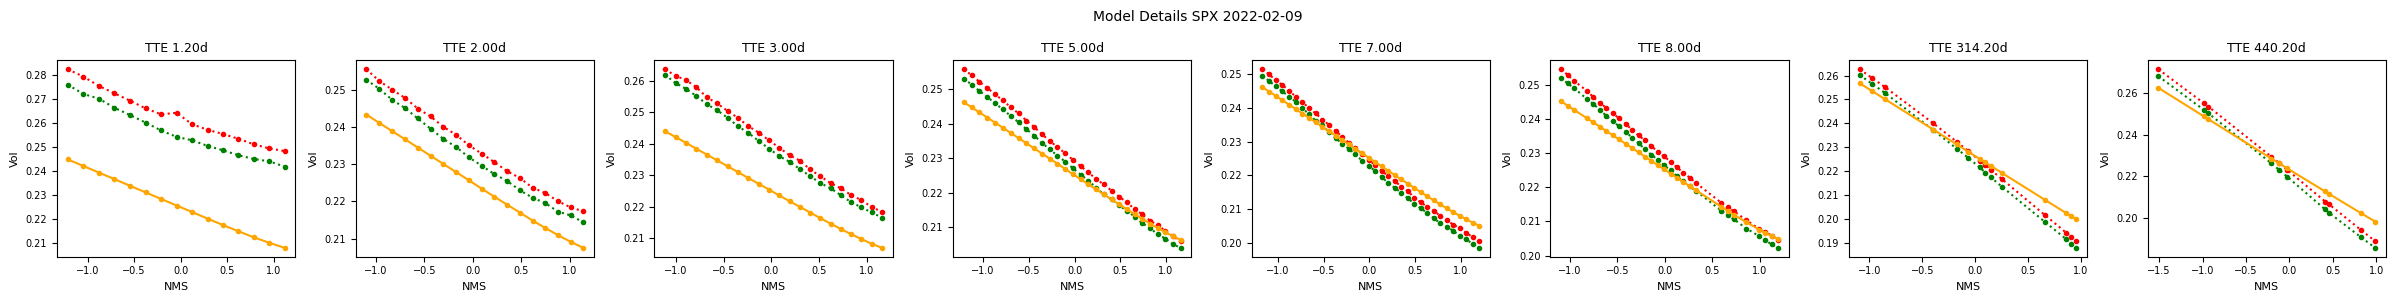

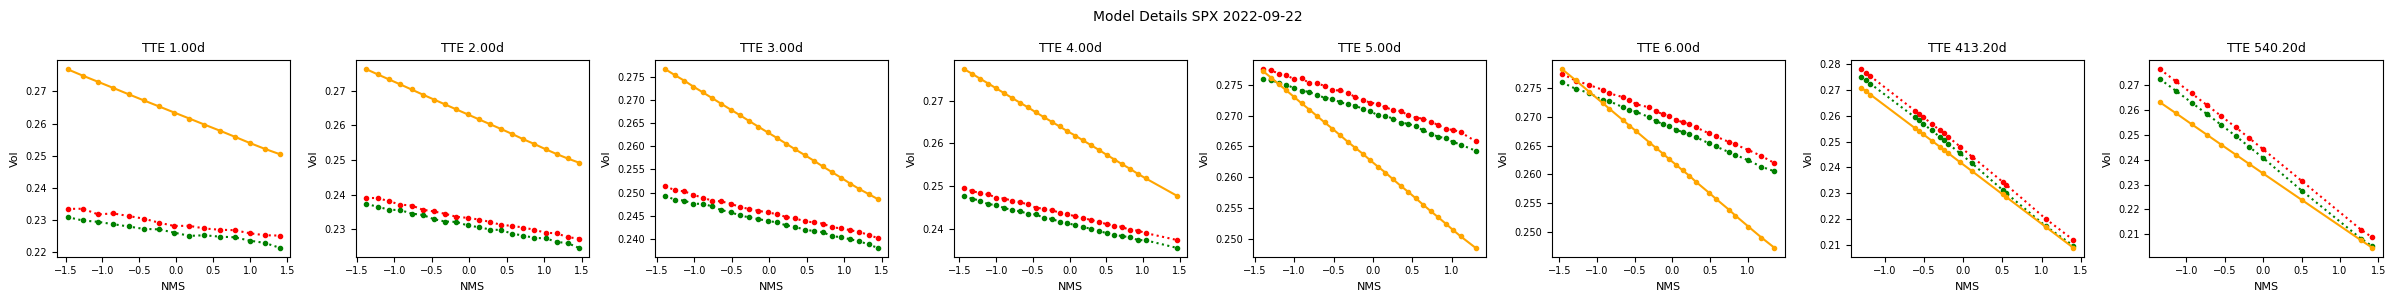

00: Training 'train_vol_vol_simple' epoch 2/1000 error avg trn 51.11; val 49.38/61.22 [26s 0.43s 0.43s]. LR: 1.00e-03, GN 8.815, excess_weighted: 0.003609/0.002956, excess_weighted_avg: 0.004124/0.003142, excess_spread: 53.43/61.27, excess_spread_avg: 49.41/61.27, excess: 0.005557/0.00357, excess_avg: 0.005207/0.00357. ETA: 8:39:55.
00: Training 'train_vol_vol_simple' epoch 3/1000 error avg trn 49.83; val 47.77/61.19 [40s 0.44s 0.43s]. LR: 1.00e-03, GN 3.562, excess_weighted: 0.003486/0.002953, excess_weighted_avg: 0.004/0.003127, excess_spread: 51.61/61.22, excess_spread_avg: 47.64/61.22, excess: 0.005311/0.003613, excess_avg: 0.004966/0.003613. ETA: 13:07:34.
00: Training 'train_vol_vol_simple' epoch 4/1000 error avg trn 47.17; val 21.15/44.03 [53s 0.44s 0.43s]. LR: 1.00e-03, GN 43.66, excess_weighted: 0.00141/0.002105, excess_weighted_avg: 0.001799/0.002151, excess_spread: 20.87/43.64, excess_spread_avg: 19.97/43.64, excess: 0.002451/0.002848, excess_avg: 0.002474/0.002848. ETA: 17:

In [ ]:
from quantdata.dysanos.simple.model import *
from quantdata.dysanos.simple.aec import *

aec_config = AEC.Config(
    # core pararmeters
    encode_what = "vol",
    fit_what    = "vol",
    num_state   = 64,
    fit_average = True,

    encoder = DeepSetEncoderFactory(
        num_compress = 128,
        inside_tanh = True,
        set_config = FeedForward.Config(
            num_depth = 2,
            num_width = 32,
            activation = 'Softplus',
        ),
        fix_config = FeedForward.Config(
            num_depth = 2,
            num_width = 64,
            activation = 'Softplus',
        )
    ),
    decoder = SimpleDecoderFactory(
        config = FeedForward.Config(
            num_depth = 2,
            num_width = 64,
            activation = 'Softplus',    
        )
    ),
)

with torch.compiler.set_stance("force_eager"):
    run( ipynbname.name(), version="1.2", aec_config=aec_config, sampler=sampler, epochs = 1000, batch_per_epoch = 100, val_batch_size=512 )
